In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import wandb

# Dataset Visualisation

There are a max of four classes in the dataset: background, object1, object2, and object3. However, some images may only contain a subset of these classes. For example, some images may only contain background and object1, while others may contain all four classes. The number of classes present in each image can vary, but it will always be between 2 and 4.

Classes in mask: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 254


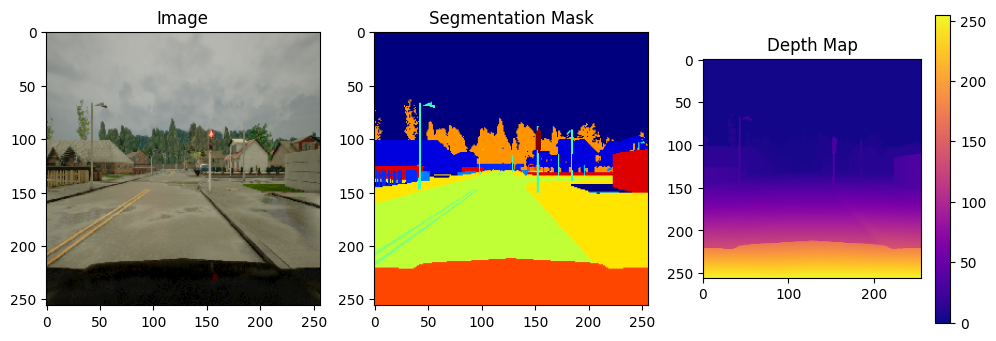

Classes in mask: [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 240


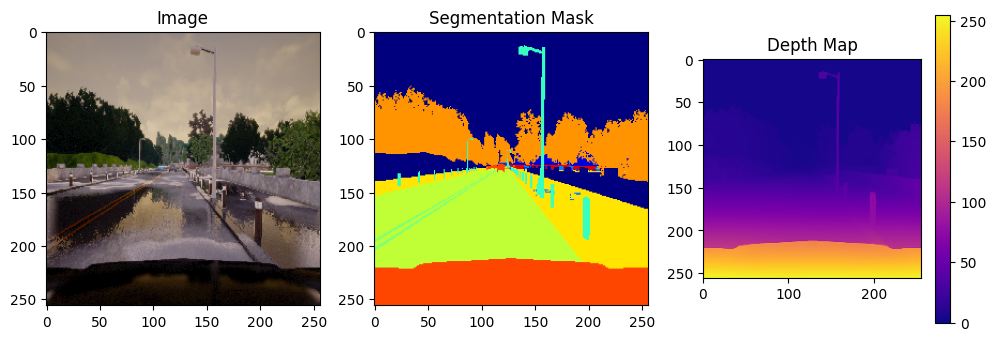

Classes in mask: [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11]
Number of unique values in depth map: 248


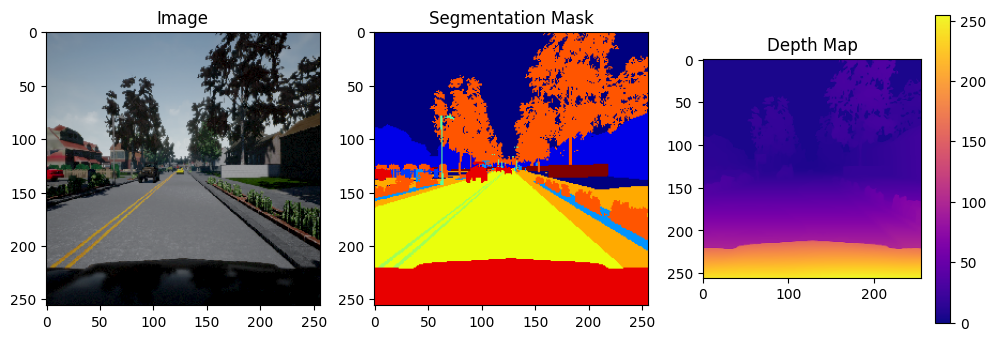

Classes in mask: [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 12]
Number of unique values in depth map: 241


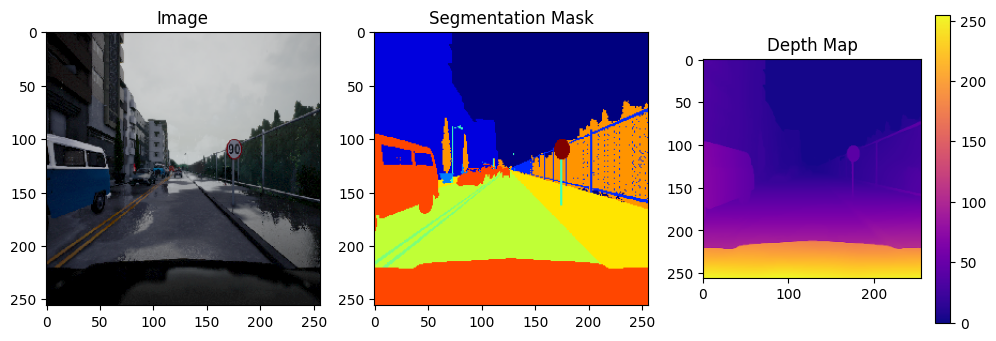

Classes in mask: [0, 1, 2, 3, 5, 7, 8, 9, 10, 12]
Number of unique values in depth map: 247


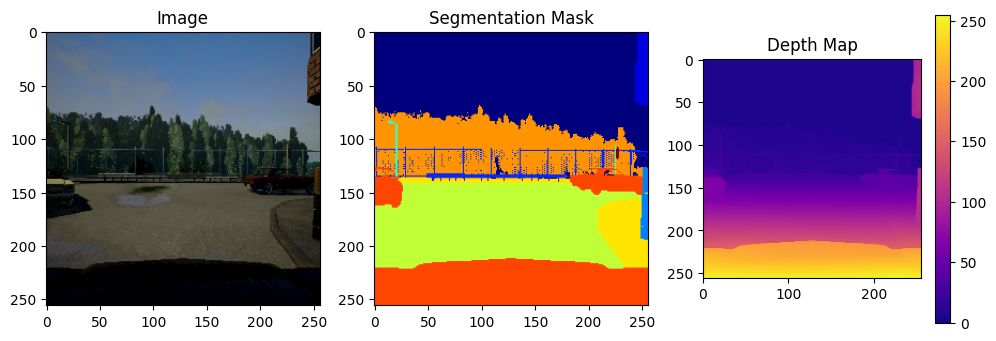

Classes in mask: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12]
Number of unique values in depth map: 244


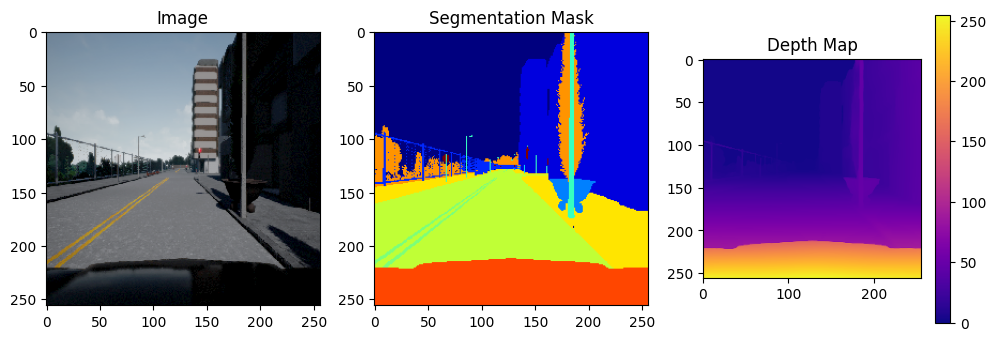

Classes in mask: [0, 2, 5, 6, 7, 8, 9, 10]
Number of unique values in depth map: 256


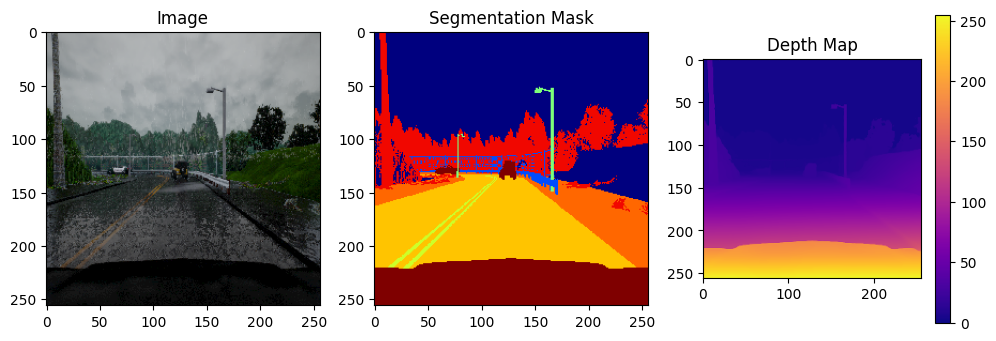

Classes in mask: [0, 2, 5, 6, 7, 8, 9, 10, 12]
Number of unique values in depth map: 255


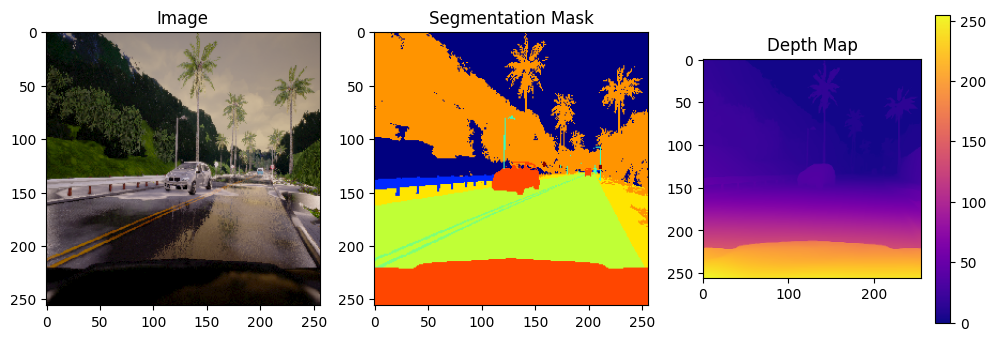

Classes in mask: [0, 1, 2, 3, 7, 8, 9, 10, 11]
Number of unique values in depth map: 244


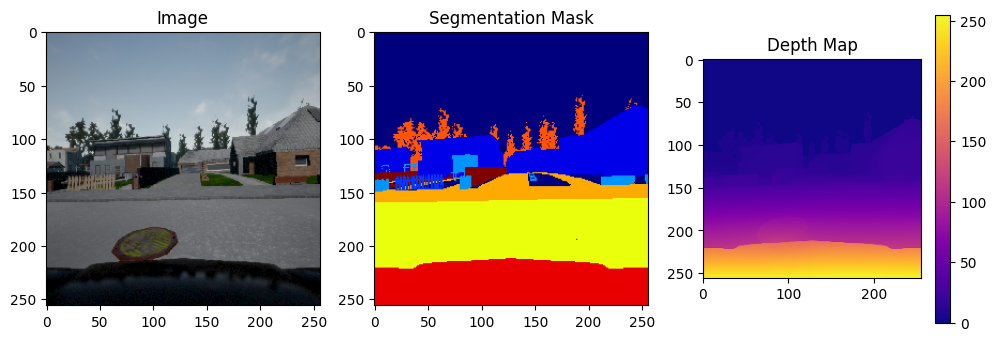

Classes in mask: [0, 1, 3, 5, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 230


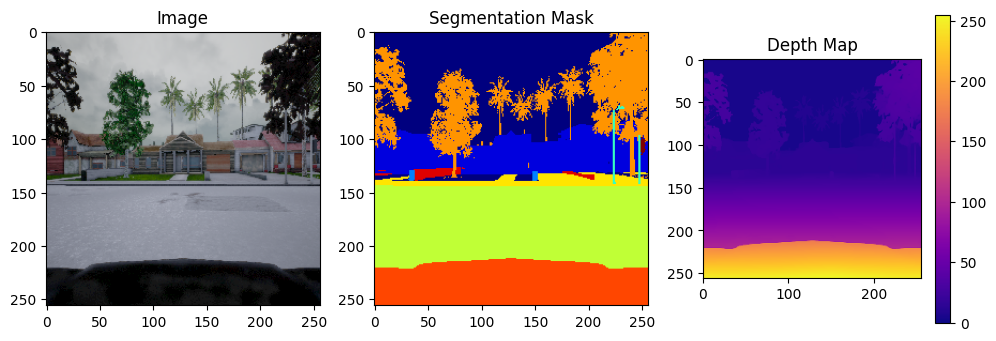

Classes in mask: [0, 2, 3, 5, 6, 7, 8, 9, 10, 12]
Number of unique values in depth map: 245


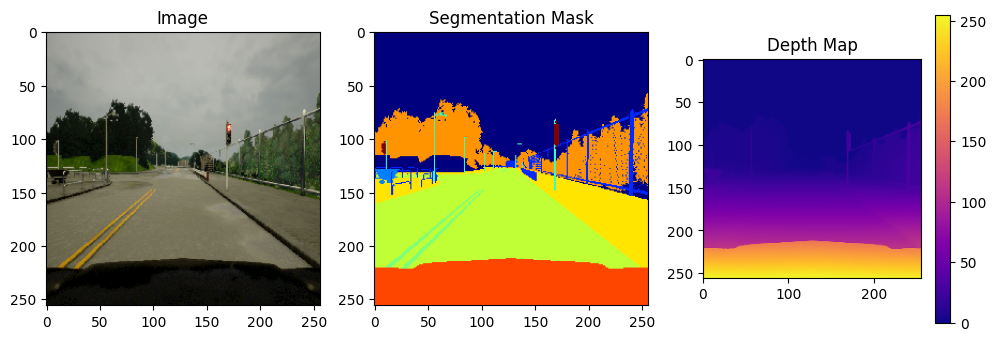

Classes in mask: [0, 1, 3, 5, 6, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 245


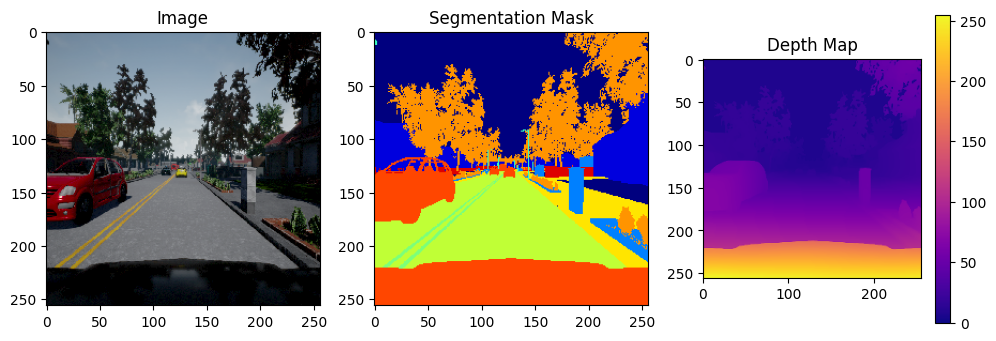

Classes in mask: [0, 1, 2, 3, 5, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 226


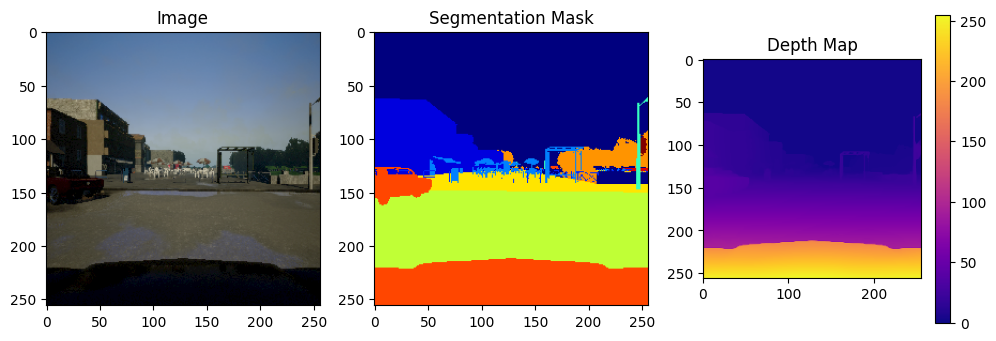

Classes in mask: [0, 2, 5, 6, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 253


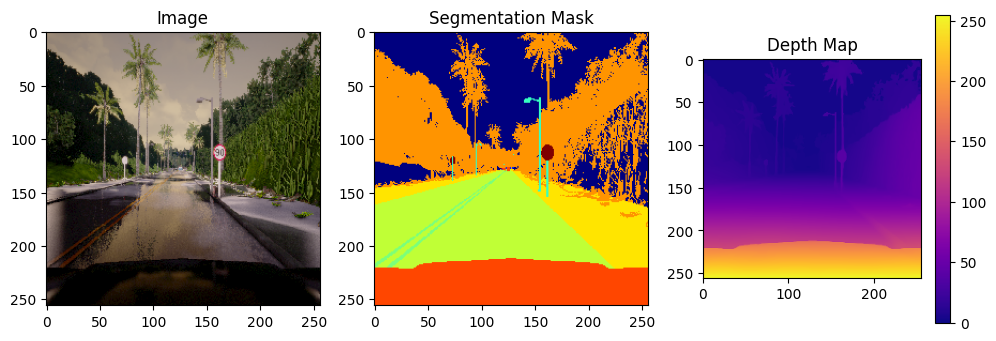

Classes in mask: [0, 2, 4, 5, 6, 7, 8, 9, 10]
Number of unique values in depth map: 256


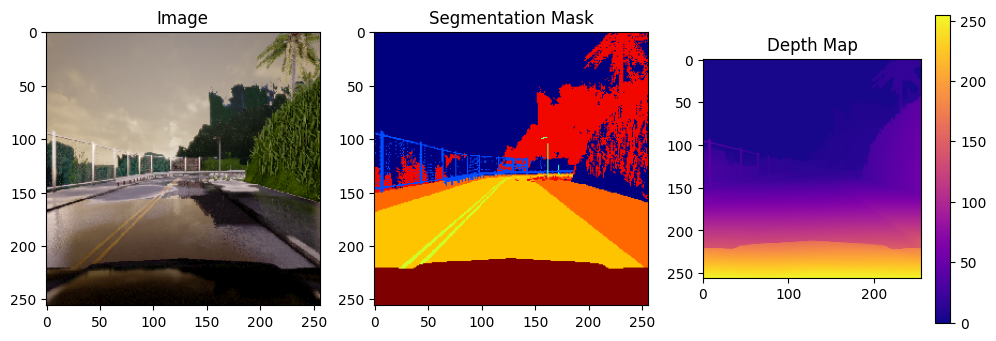

Classes in mask: [0, 1, 2, 3, 5, 6, 7, 8, 9, 10]
Number of unique values in depth map: 256


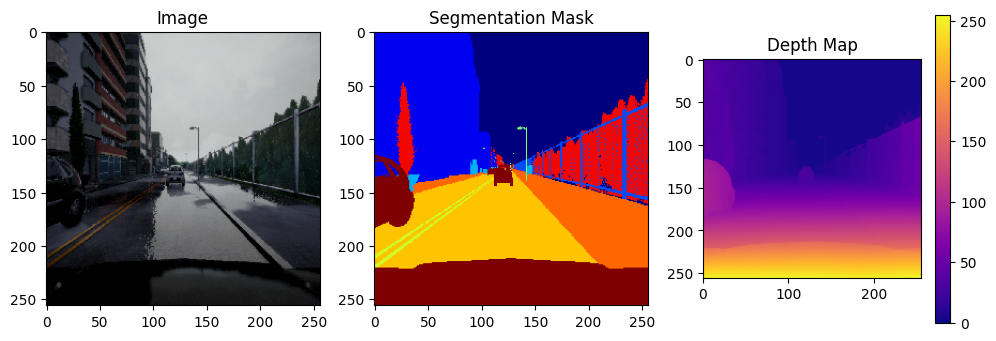

Classes in mask: [0, 1, 2, 5, 6, 7, 8, 9, 10]
Number of unique values in depth map: 244


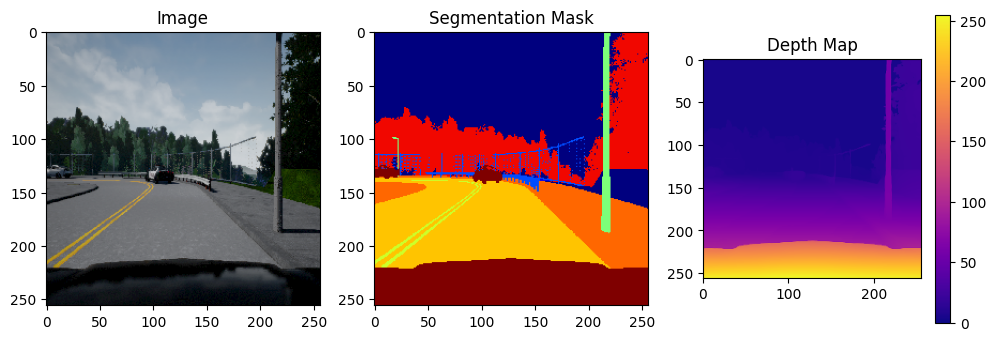

Classes in mask: [0, 1, 2, 3, 5, 7, 8, 9, 10]
Number of unique values in depth map: 256


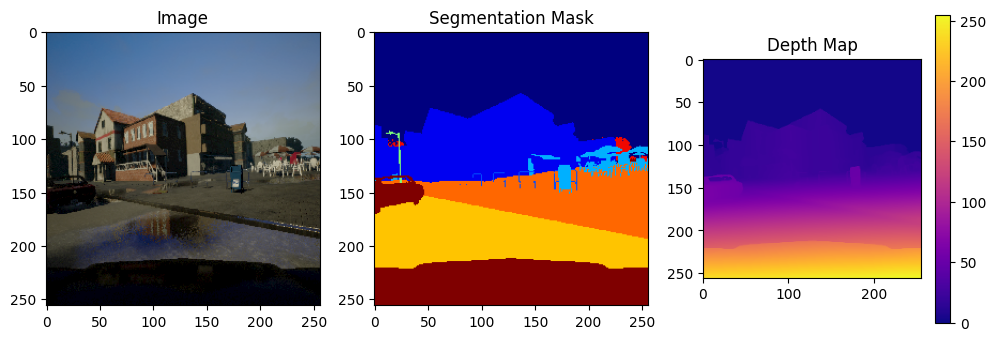

Classes in mask: [0, 2, 5, 7, 8, 9, 10, 12]
Number of unique values in depth map: 239


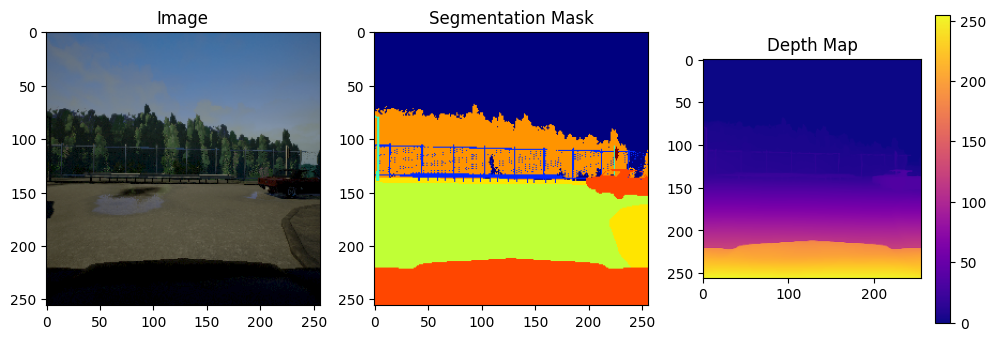

Classes in mask: [0, 2, 3, 5, 6, 7, 8, 9, 10]
Number of unique values in depth map: 237


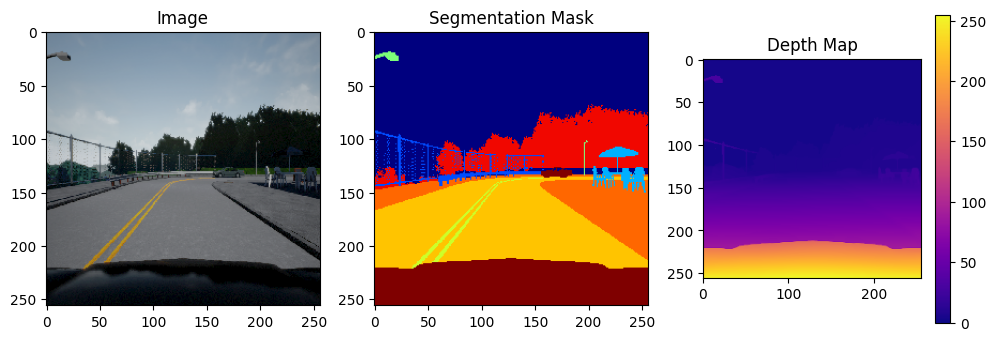

Classes in mask: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Number of unique values in depth map: 242


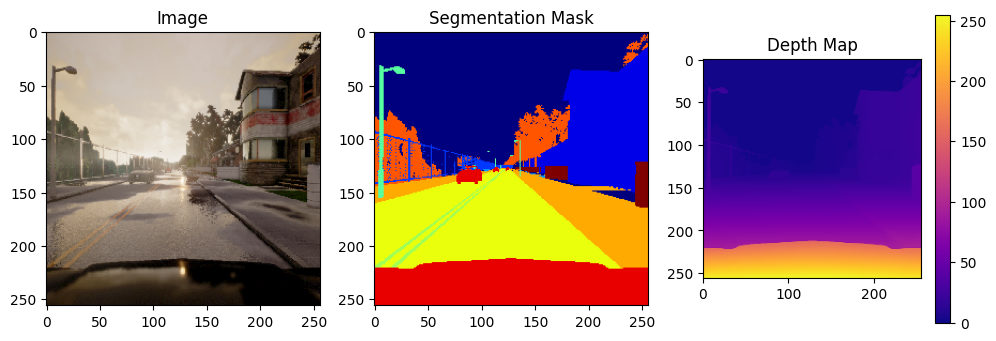

Classes in mask: [0, 2, 6, 7, 8, 9, 10]
Number of unique values in depth map: 241


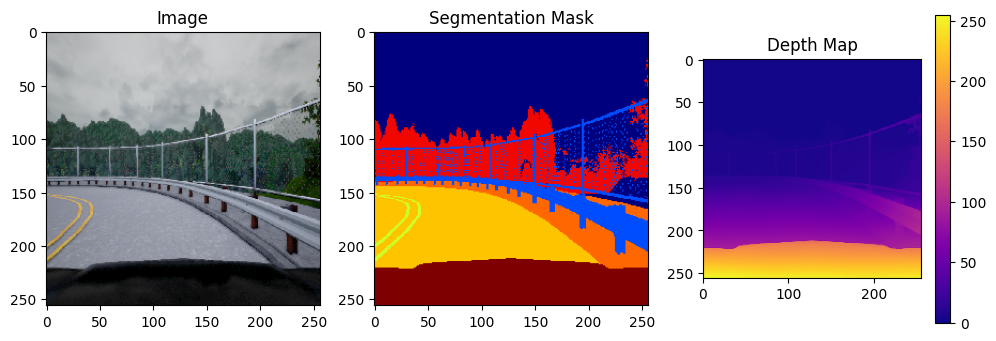

Classes in mask: [0, 1, 2, 7, 8, 9, 10]
Number of unique values in depth map: 239


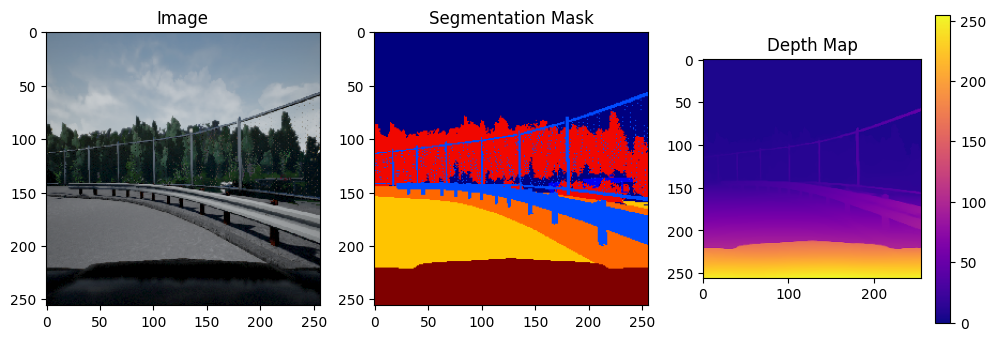

Classes in mask: [0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 247


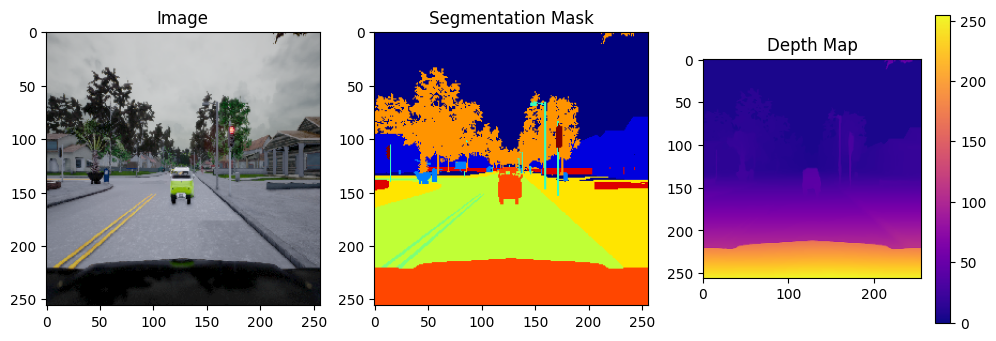

Classes in mask: [0, 2, 7, 8, 9, 10]
Number of unique values in depth map: 245


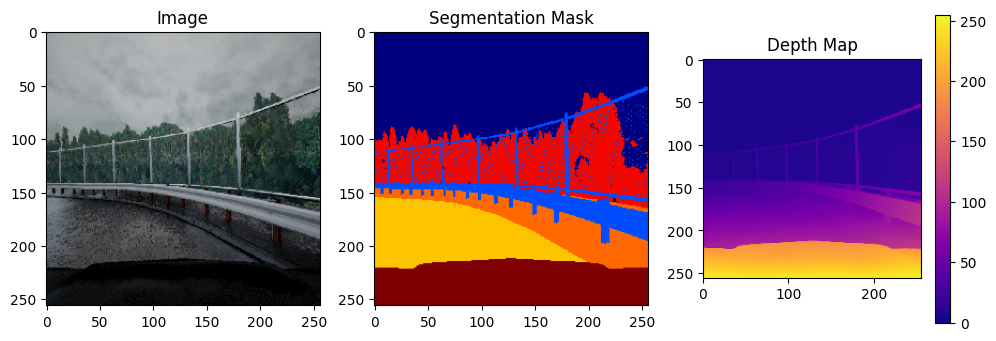

Classes in mask: [0, 1, 2, 5, 7, 8, 9, 10]
Number of unique values in depth map: 241


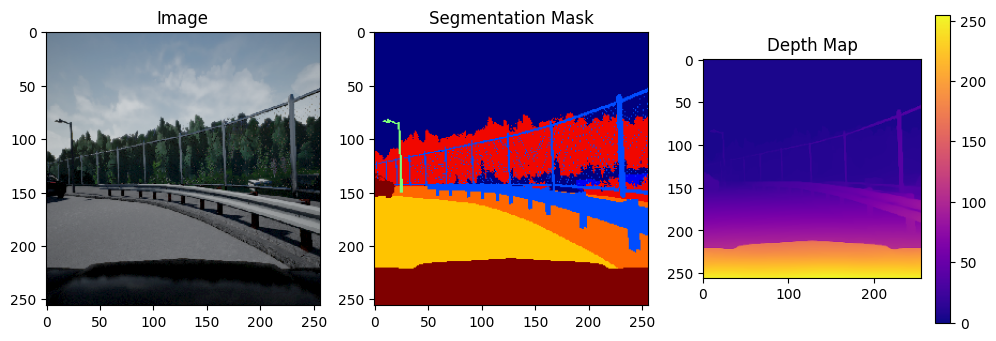

Classes in mask: [0, 1, 2, 6, 7, 8, 9, 10]
Number of unique values in depth map: 239


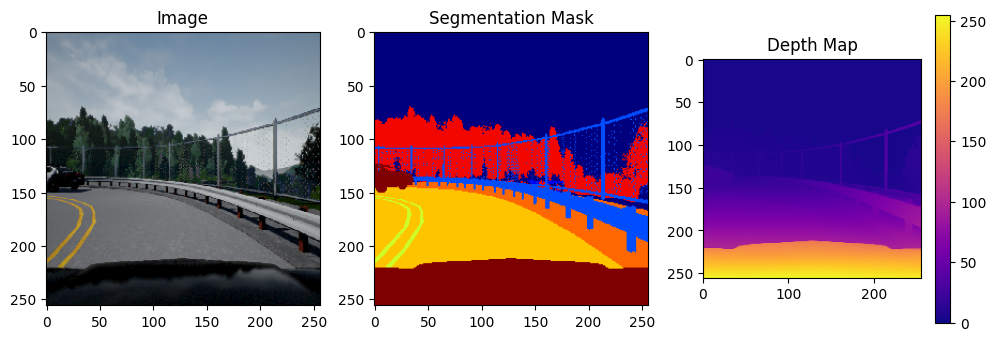

Classes in mask: [0, 1, 2, 3, 5, 7, 8, 9, 10, 11]
Number of unique values in depth map: 232


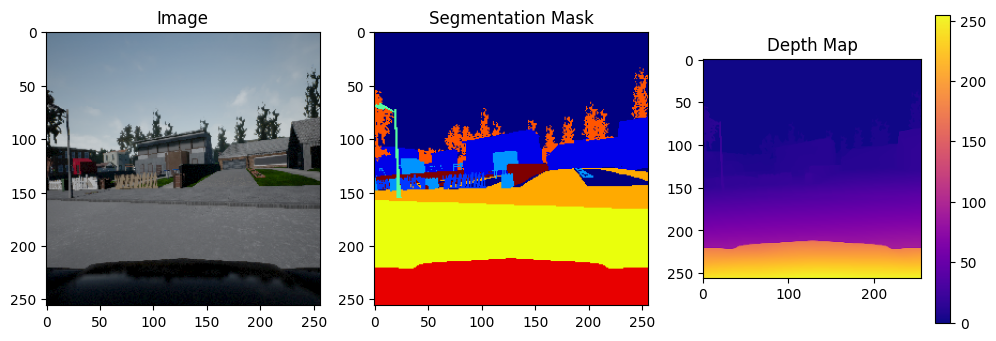

Classes in mask: [0, 1, 2, 5, 6, 7, 8, 9, 10, 11, 12]
Number of unique values in depth map: 249


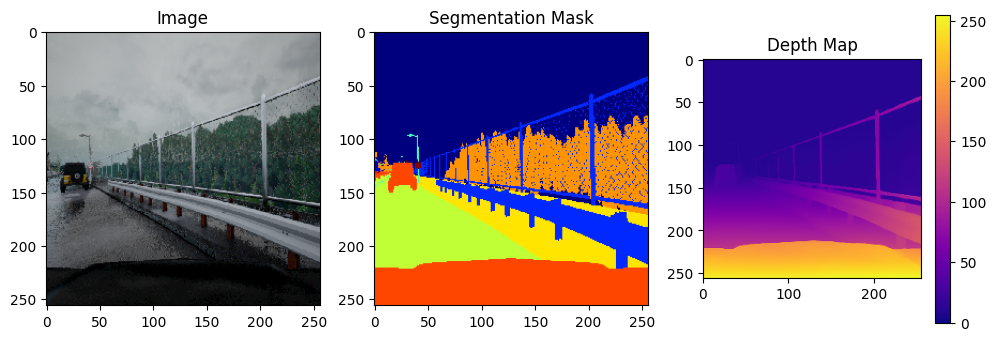

Classes in mask: [0, 1, 2, 5, 7, 8, 9, 10, 12]
Number of unique values in depth map: 234


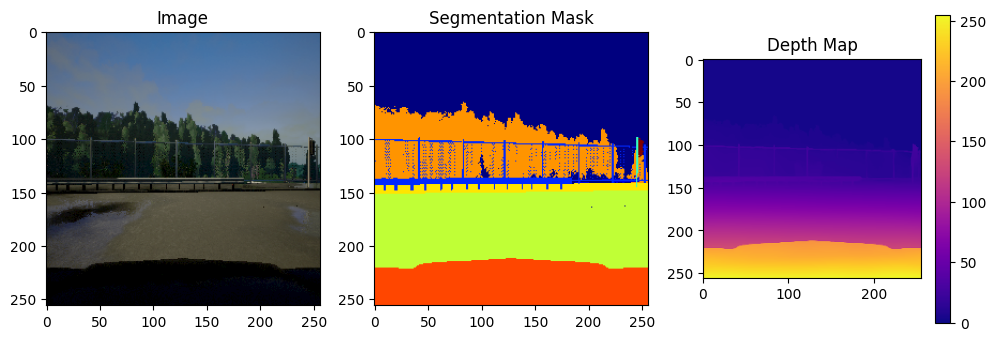

Classes in mask: [0, 1, 3, 7, 8, 9, 10, 11]
Number of unique values in depth map: 235


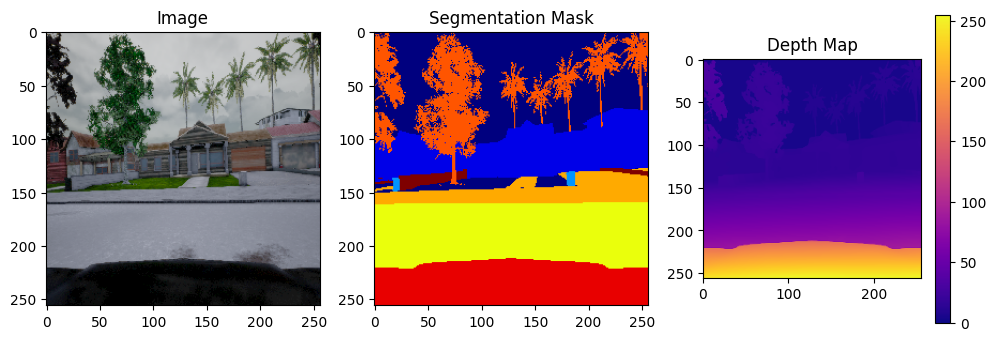

Classes in mask: [0, 1, 3, 5, 7, 8, 9, 10, 11]
Number of unique values in depth map: 237


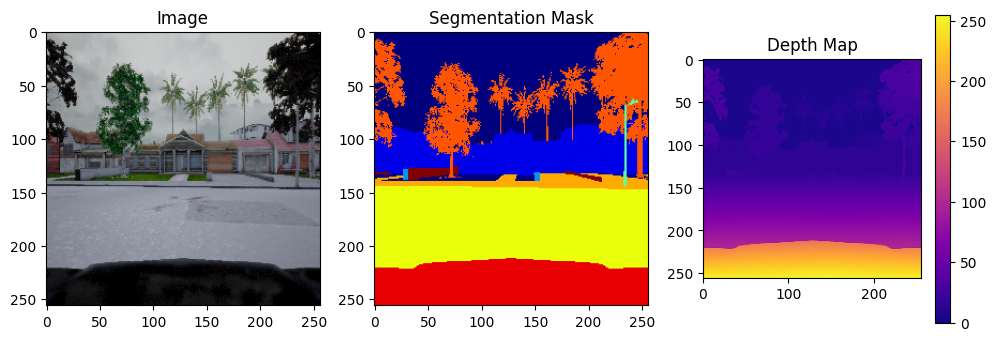

Classes in mask: [0, 1, 2, 5, 6, 7, 8, 9, 10, 12]
Number of unique values in depth map: 226


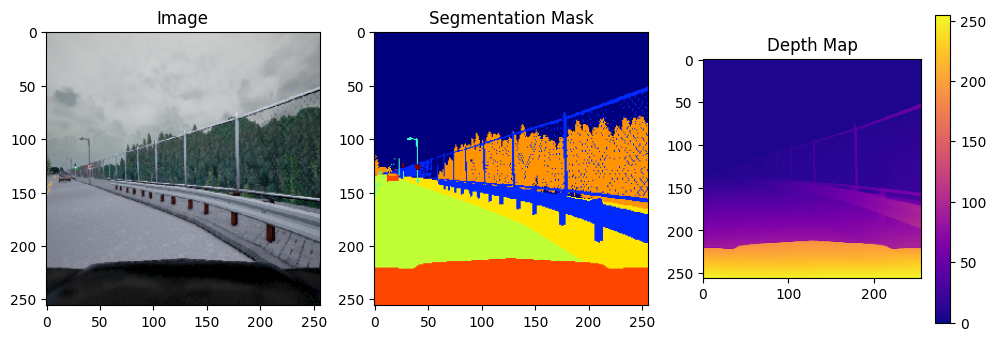

In [2]:
# Visualise a few images to understand the dataset better.

root = "data/train"

alr_visualised = []
for img_index in range(2000):  
    img_path = os.path.join(root, "images", os.listdir(root + "/images")[img_index])
    mask_path = os.path.join(root, "labels", os.listdir(root + "/labels")[img_index])
    depth_path = os.path.join(root, "depth", os.listdir(root + "/depth")[img_index])

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path)
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)[:,:,0]

    depth = cv2.imread(depth_path, cv2.IMREAD_GRAYSCALE).astype(np.float32)

    classes = np.unique(mask).tolist()
    if classes in alr_visualised:
        continue
    alr_visualised.append(classes)

    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    plt.title("Image")
    plt.imshow(img)

    plt.subplot(1,3,2)
    plt.title("Segmentation Mask")
    plt.imshow(mask, cmap='jet')
    print("Classes in mask:", classes)

    plt.subplot(1,3,3)
    plt.title("Depth Map")
    plt.imshow(depth, cmap='plasma')
    plt.colorbar()
    print("Number of unique values in depth map:", np.unique(depth).size)

    plt.show()

In [3]:
class MultiTaskDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root = root_dir
        self.transform = transform

        self.images = sorted(os.listdir(os.path.join(root_dir, "images")))
        self.masks = sorted(os.listdir(os.path.join(root_dir, "labels")))
        self.depths = sorted(os.listdir(os.path.join(root_dir, "depth")))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root, "images", self.images[idx])
        mask_path = os.path.join(self.root, "labels", self.masks[idx])
        depth_path = os.path.join(self.root, "depth", self.depths[idx])

        # Image
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = img.astype(np.float32) / 255.0

        # Mask
        mask = cv2.imread(mask_path)
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)[:,:,0]
        mask = mask.astype(np.int64)

        # Depth
        depth = cv2.imread(depth_path, cv2.IMREAD_GRAYSCALE).astype(np.float32)

        # Normalization (global-like)
        depth = depth / 255.0   # assuming 8-bit depth

        # To tensor
        img = torch.from_numpy(img).permute(2, 0, 1)
        mask = torch.from_numpy(mask)
        depth = torch.from_numpy(depth).unsqueeze(0)

        return img, mask, depth

Depth maps were normalized using a fixed scaling factor (256) instead of per-image normalization to preserve relative depth consistency across samples.

In [4]:
full_dataset = MultiTaskDataset(root_dir="data/train")
test_dataset = MultiTaskDataset(root_dir="data/test")

val_size = int(0.25 * len(full_dataset))
train_size = len(full_dataset) - val_size

generator = torch.Generator().manual_seed(42)  # reproducible split
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size], generator=generator
)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(f"Train samples: {len(train_dataset)}")
print(f"Val samples: {len(val_dataset)}")

Train samples: 1500
Val samples: 500


In [5]:
img, mask, depth = train_dataset[0]
print("Image shape:", img.shape)
print("Mask shape:", mask.shape)
print("Depth shape:", depth.shape)

Image shape: torch.Size([3, 256, 256])
Mask shape: torch.Size([256, 256])
Depth shape: torch.Size([1, 256, 256])


----

# Model Architecture

In [6]:
# Basic conv block
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU()
        )

    def forward(self, x):
        return self.net(x)

In [7]:
class UNet(nn.Module):
    def __init__(self, num_classes=13):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(128, 64)

        # Heads
        self.seg_head = nn.Conv2d(64, num_classes, kernel_size=1)
        self.depth_head = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        seg = self.seg_head(d1)
        depth = self.depth_head(d1)

        return seg, depth

Segmentation head

Output: (B, num_classes, H, W)

Loss: CrossEntropyLoss (no softmax needed)

Depth head

Output: (B, 1, H, W)

Loss: MSELoss

---

# Helper Functions

In [8]:
# class MultiTaskLoss(nn.Module):
#     def __init__(self):
#         super().__init__()

#         # log(sigma^2)
#         self.log_var_seg = nn.Parameter(torch.zeros(1))
#         self.log_var_depth = nn.Parameter(torch.zeros(1))

#     def forward(self, seg_pred, seg_gt, depth_pred, depth_gt):
#         seg_loss = F.cross_entropy(seg_pred, seg_gt)
#         depth_loss = F.mse_loss(depth_pred, depth_gt)

#         loss = seg_loss + 0.1 * depth_loss

#         return loss, seg_loss, depth_loss    

In [9]:
class MultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()

        # log(sigma^2)
        self.log_var_seg = nn.Parameter(torch.zeros(1))
        self.log_var_depth = nn.Parameter(torch.zeros(1))

    def forward(self, seg_pred, seg_gt, depth_pred, depth_gt):
        seg_loss = F.cross_entropy(seg_pred, seg_gt)
        depth_loss = F.mse_loss(depth_pred, depth_gt)

        # uncertainty weighting
        loss = (
            torch.exp(-self.log_var_seg) * seg_loss + self.log_var_seg +
            torch.exp(-self.log_var_depth) * depth_loss + self.log_var_depth
        )
        loss += 0.01 * (self.log_var_seg**2 + self.log_var_depth**2)

        return loss, seg_loss, depth_loss

In [10]:
# class MultiTaskLoss(nn.Module):
#     def __init__(self, num_classes=13):
#         super().__init__()

#         self.num_classes = num_classes

#         # per-class uncertainty
#         self.log_var_seg = nn.Parameter(torch.zeros(num_classes))
#         self.log_var_depth = nn.Parameter(torch.zeros(1))

#     def forward(self, seg_pred, seg_gt, depth_pred, depth_gt):
#         B, C, H, W = seg_pred.shape

#         # ---------------- SEGMENTATION ----------------
#         seg_loss = F.cross_entropy(seg_pred, seg_gt, reduction='none')  # (B,H,W)

#         seg_gt_onehot = F.one_hot(seg_gt, C).permute(0,3,1,2)  # (B,C,H,W)

#         seg_loss_per_class = (seg_loss.unsqueeze(1) * seg_gt_onehot).sum(dim=(0,2,3))
#         counts = seg_gt_onehot.sum(dim=(0,2,3)) + 1e-8

#         seg_loss_per_class = seg_loss_per_class / counts  # (C,)

#         # uncertainty weighting per class
#         seg_weighted = torch.exp(-self.log_var_seg) * seg_loss_per_class + self.log_var_seg
#         seg_loss_final = seg_weighted.sum()

#         # ---------------- DEPTH ----------------
#         depth_loss = F.mse_loss(depth_pred, depth_gt)

#         depth_loss_final = (
#             torch.exp(-self.log_var_depth) * depth_loss + self.log_var_depth
#         )

#         # ---------------- TOTAL ----------------
#         loss = seg_loss_final + depth_loss_final

#         # regularization (important!)
#         loss += 0.01 * (
#             (self.log_var_seg**2).sum() + self.log_var_depth**2
#         )

#         return loss, seg_loss_final, depth_loss_final

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
def compute_alpha(dataloader):
    class_counts = torch.zeros(13)
    total_pixels = 0

    for _, masks, _ in dataloader:
        for mask in masks:
            mask = mask.to(device)
            for c in range(13):
                class_counts[c] += (mask == c).sum().item()
            total_pixels += mask.numel()

    class_freqs = class_counts / total_pixels
    alpha = 1.0 / (class_freqs + 1e-8)
    alpha = alpha / alpha.sum() * 13

    return alpha

alpha = compute_alpha(train_loader)
print("Class weights (alpha):", alpha)

Class weights (alpha): tensor([2.4339e-03, 9.0570e-03, 7.5040e-02, 7.4471e-02, 1.1497e+01, 1.5541e-01,
        1.0105e-01, 3.9135e-03, 9.5874e-03, 6.1428e-03, 4.5486e-03, 1.0488e-01,
        9.5654e-01])


In [13]:
# class FocalLoss(torch.nn.Module):
#     def __init__(self, gamma=2.0, alpha=None, ignore_index=255):
#         super().__init__()
#         self.gamma = gamma
#         self.alpha = alpha.to(device) if alpha is not None else None
#         self.ignore_index = ignore_index

#     def forward(self, logits, targets):
#         ce_loss = F.cross_entropy(
#             logits, targets, reduction='none', ignore_index=self.ignore_index
#         )
        
#         pt = torch.exp(-ce_loss)  # pt = softmax prob of correct class
#         focal_loss = (1 - pt) ** self.gamma * ce_loss

#         if self.alpha is not None:
#             alpha_t = self.alpha.gather(0, targets.view(-1))
#             focal_loss = focal_loss.view(-1) * alpha_t
#             focal_loss = focal_loss.view_as(targets)

#         return focal_loss.mean()

In [14]:
# class MultiTaskLoss(torch.nn.Module):
#     def __init__(self):
#         super().__init__()
#         self.focal_loss_fn = FocalLoss(gamma=2.0, alpha=alpha)
#         self.seg_loss_fn = nn.MSELoss()

#         self.log_var_seg = torch.nn.Parameter(torch.zeros(1))
#         self.log_var_depth = torch.nn.Parameter(torch.zeros(1))

#     def forward(self, seg_pred, seg_gt, depth_pred, depth_gt):
#         seg_loss = self.focal_loss_fn(seg_pred, seg_gt)
#         depth_loss = self.seg_loss_fn(depth_pred, depth_gt)

#         # loss = (
#         #     torch.exp(-self.log_var_seg) * seg_loss +
#         #     torch.exp(-self.log_var_depth) * depth_loss +
#         #     self.log_var_seg + self.log_var_depth
#         # )

#         loss = seg_loss + 0.5 * depth_loss

#         return loss, seg_loss, depth_loss

In [15]:
def compute_miou(pred, target, num_classes):
    pred = torch.argmax(pred, dim=1)

    ious = []
    for cls in range(num_classes):
        intersection = ((pred == cls) & (target == cls)).sum().float()
        union = ((pred == cls) | (target == cls)).sum().float()

        if union == 0:
            continue

        ious.append(intersection / union)

    return sum(ious) / len(ious) if ious else torch.tensor(0.0)


def compute_rmse(pred, target):
    return torch.sqrt(F.mse_loss(pred, target))

In [16]:
def log_predictions_batch(imgs, masks, depths, seg_pred, depth_pred, step, num_samples=10):
    imgs = imgs.cpu()
    masks = masks.cpu()
    depths = depths.cpu()
    seg_pred = seg_pred.cpu()
    depth_pred = depth_pred.cpu()

    num_samples = min(num_samples, imgs.shape[0])
    images_to_log = []

    for i in range(num_samples):
        img = imgs[i].permute(1,2,0).numpy()
        gt_mask = masks[i].numpy()
        pred_mask = torch.argmax(seg_pred[i], dim=0).numpy()

        gt_depth = depths[i].squeeze().numpy()
        pred_depth = depth_pred[i].squeeze().numpy()

        fig, axs = plt.subplots(1, 5, figsize=(15,3))

        axs[0].imshow(img)
        axs[0].set_title("Image")

        axs[1].imshow(gt_mask, cmap='jet')
        axs[1].set_title("GT Mask")

        axs[2].imshow(pred_mask, cmap='jet')
        axs[2].set_title("Pred Mask")

        axs[3].imshow(gt_depth, cmap='plasma')
        axs[3].set_title("GT Depth")

        axs[4].imshow(pred_depth, cmap='plasma')
        axs[4].set_title("Pred Depth")

        for ax in axs:
            ax.axis("off")

        images_to_log.append(wandb.Image(fig))
        plt.close(fig)

    wandb.log({"Predictions": images_to_log}, step=step)

In [17]:
def eval_model(model, dataloader, loss_fn, step):
    model.eval()
    val_loss = 0
    val_miou = 0
    val_rmse = 0
    val_seg_loss = 0
    val_depth_loss = 0

    with torch.no_grad():
        for i, (imgs, masks, depths) in enumerate(dataloader):
            imgs = imgs.to(device)
            masks = masks.to(device)
            depths = depths.to(device)

            seg_pred, depth_pred = model(imgs)

            # log only first batch
            if i == 0:
                log_predictions_batch(imgs, masks, depths, seg_pred, depth_pred, step=step)

            loss, seg_loss, depth_loss = loss_fn(seg_pred, masks, depth_pred, depths)

            val_loss += loss.item()
            val_miou += compute_miou(seg_pred, masks, 4).item()
            val_rmse += compute_rmse(depth_pred, depths).item()
            val_seg_loss += seg_loss.item()
            val_depth_loss += depth_loss.item()

    val_loss /= len(dataloader)
    val_miou /= len(dataloader)
    val_rmse /= len(dataloader)
    val_seg_loss /= len(dataloader)
    val_depth_loss /= len(dataloader)

    print(f"Val Loss={val_loss:.4f}, mIoU={val_miou:.4f}, RMSE={val_rmse:.4f}")
    print(f"Segmentation Loss={val_seg_loss:.4f}, Depth Loss={val_depth_loss:.4f}")

    wandb.log({
        "val_loss": val_loss,
        "val_mIoU": val_miou,
        "val_RMSE": val_rmse,
        "seg_loss": val_seg_loss,
        "depth_loss": val_depth_loss,
    }, step=step)

In [18]:
def train_model(model, train_loader, val_loader, num_epochs, lr):
    loss_fn = MultiTaskLoss().to(device)
    optimizer = torch.optim.Adam(
        list(model.parameters()) + list(loss_fn.parameters()),
        lr=lr
    )

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0
        train_miou = 0
        train_rmse = 0
        train_seg_loss = 0
        train_depth_loss = 0

        for imgs, masks, depths in tqdm(train_loader):
            imgs = imgs.to(device)
            masks = masks.to(device)
            depths = depths.to(device)

            seg_pred, depth_pred = model(imgs)

            loss, seg_loss, depth_loss = loss_fn(
                seg_pred, masks, depth_pred, depths
            )

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_miou += compute_miou(seg_pred, masks, 4).item()
            train_rmse += compute_rmse(depth_pred, depths).item()
            train_seg_loss += seg_loss.item()
            train_depth_loss += depth_loss.item()

        train_loss /= len(train_loader)
        train_miou /= len(train_loader)
        train_rmse /= len(train_loader)
        train_seg_loss /= len(train_loader)
        train_depth_loss /= len(train_loader)

        print(f"Epoch {epoch}: "f"Train Loss={train_loss:.4f}, "f"mIoU={train_miou:.4f}, RMSE={train_rmse:.4f}")
        eval_model(model, val_loader, loss_fn, step=epoch)
        
        wandb.log({
            "epoch": epoch,

            "train_loss": train_loss,
            "train_mIoU": train_miou,
            "train_RMSE": train_rmse,

            # individual losses
            "train_seg_loss": train_seg_loss,
            "train_depth_loss": train_depth_loss,

            # learnable weights
            "log_var_seg": loss_fn.log_var_seg.item(),
            "log_var_depth": loss_fn.log_var_depth.item()
        }, step=epoch)

        # for i in range(loss_fn.num_classes):
        #     wandb.log({
        #         f"log_var_seg_class_{i}": loss_fn.log_var_seg[i].item()
        #     }, step=epoch)

---
# Task 2.1

In [ ]:
num_epochs = 50

In [20]:
model = UNet(num_classes=13).to(device)

wandb.init(
    project="multitask-unet",
    name="Vanilla UNet",
    config={
        "lr": 1e-4,
        "batch_size": 16,
        "epochs": 20
    }
)
train_model(model,  train_loader, val_loader, num_epochs=num_epochs, lr=1e-4)
wandb.finish()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home2/ameyk/.netrc.
wandb: Currently logged in as: ameykaran (iiith-ameykaran) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


100%|██████████| 94/94 [00:37<00:00,  2.48it/s]


Epoch 0: Train Loss=1.4161, mIoU=0.2879, RMSE=0.1487
Val Loss=1.0541, mIoU=0.4014, RMSE=0.1183
Segmentation Loss=1.0498, Depth Loss=0.0140


100%|██████████| 94/94 [00:36<00:00,  2.54it/s]


Epoch 1: Train Loss=0.7916, mIoU=0.4067, RMSE=0.0941
Val Loss=0.7002, mIoU=0.4180, RMSE=0.0850
Segmentation Loss=0.7116, Depth Loss=0.0072


100%|██████████| 94/94 [00:36<00:00,  2.60it/s]


... (92 outputs left out)

Epoch 48: Train Loss=-0.8769, mIoU=0.8999, RMSE=0.0342
Val Loss=-0.8585, mIoU=0.8651, RMSE=0.0343
Segmentation Loss=0.0475, Depth Loss=0.0012


100%|██████████| 94/94 [00:36<00:00,  2.55it/s]


Epoch 49: Train Loss=-0.8968, mIoU=0.9031, RMSE=0.0341
Val Loss=-0.8760, mIoU=0.8662, RMSE=0.0341
Segmentation Loss=0.0479, Depth Loss=0.0012


depth_loss,█▃▃▂▂▂▂▂▂▂▂▂▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁
epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇███
log_var_depth,████▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▁▁▁
log_var_seg,████▇▇▇▇▆▆▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁
seg_loss,█▆▄▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
train_RMSE,█▅▄▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁
train_depth_loss,█▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁
train_loss,█▆▅▅▅▄▄▄▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁
train_mIoU,▁▂▃▃▃▄▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇████████▆▇▇███████
train_seg_loss,█▅▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
+3,...


---

# Task 2.2

In [21]:
class UNetNoSkip(nn.Module):
    def __init__(self, num_classes=13):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(3, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ConvBlock(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = ConvBlock(512, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = ConvBlock(256, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = ConvBlock(128, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = ConvBlock(64, 64)

        # Heads
        self.seg_head = nn.Conv2d(64, num_classes, kernel_size=1)
        self.depth_head = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = self.dec1(d1)

        seg = self.seg_head(d1)
        depth = self.depth_head(d1)

        return seg, depth

In [22]:
model = UNetNoSkip(num_classes=13).to(device)

wandb.init(
    project="multitask-unet",
    name="NoSkip UNet",
    config={
        "lr": 1e-4,
        "batch_size": 16,
        "epochs": 20
    }
)
train_model(model,  train_loader, val_loader, num_epochs=num_epochs, lr=1e-4)
wandb.finish()

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


100%|██████████| 94/94 [00:32<00:00,  2.88it/s]


Epoch 0: Train Loss=1.4143, mIoU=0.2641, RMSE=0.1774
Val Loss=0.8983, mIoU=0.3655, RMSE=0.1079
Segmentation Loss=0.8957, Depth Loss=0.0117


100%|██████████| 94/94 [00:32<00:00,  2.93it/s]


Epoch 1: Train Loss=0.7607, mIoU=0.3945, RMSE=0.0850
Val Loss=0.6904, mIoU=0.3930, RMSE=0.0792
Segmentation Loss=0.7032, Depth Loss=0.0063


100%|██████████| 94/94 [00:32<00:00,  2.92it/s]


... (92 outputs left out)

Epoch 48: Train Loss=-0.6044, mIoU=0.5938, RMSE=0.0518
Val Loss=-0.6220, mIoU=0.6128, RMSE=0.0503
Segmentation Loss=0.1890, Depth Loss=0.0026


100%|██████████| 94/94 [00:32<00:00,  2.90it/s]


Epoch 49: Train Loss=-0.6883, mIoU=0.6649, RMSE=0.0474
Val Loss=-0.6826, mIoU=0.6387, RMSE=0.0473
Segmentation Loss=0.1611, Depth Loss=0.0023


depth_loss,█▄▃▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▅▃▂
epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇███
log_var_depth,████▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▁▁▁
log_var_seg,███▇▇▇▇▇▆▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁▁
seg_loss,█▆▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▂▁
train_RMSE,█▄▃▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂
train_depth_loss,█▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▁
train_loss,█▆▅▅▅▄▄▄▄▄▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁▁▁▂▂▁
train_mIoU,▁▃▃▃▄▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█████████████▆▄▆
train_seg_loss,█▅▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂
+3,...


---

# Part 2.3

In [23]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
        )

        if in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, kernel_size=1)
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        identity = self.skip(x)
        out = self.net(x)
        out = out + identity
        return F.relu(out)

In [24]:
class UNetResidual(nn.Module):
    def __init__(self, num_classes=13):
        super().__init__()

        # Encoder
        self.enc1 = ResidualBlock(3, 64)
        self.enc2 = ResidualBlock(64, 128)
        self.enc3 = ResidualBlock(128, 256)
        self.enc4 = ResidualBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = ResidualBlock(512, 1024)

        # Decoder
        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = ResidualBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = ResidualBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = ResidualBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = ResidualBlock(128, 64)

        # Heads
        self.seg_head = nn.Conv2d(64, num_classes, 1)
        self.depth_head = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        # Decoder
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        seg = self.seg_head(d1)
        depth = self.depth_head(d1)

        return seg, depth

In [25]:
model = UNetResidual(num_classes=13).to(device)
x = torch.randn(2, 3, 256, 256).to(device)

seg, depth = model(x)

print(seg.shape, depth.shape)

torch.Size([2, 13, 256, 256]) torch.Size([2, 1, 256, 256])


In [26]:
wandb.init(
    project="multitask-unet",
    name="Residual UNet",
    config={
        "lr": 1e-4,
        "batch_size": 16,
        "epochs": 20
    }
)
train_model(model,  train_loader, val_loader, num_epochs=num_epochs, lr=1e-4)
wandb.finish()

100%|██████████| 94/94 [00:44<00:00,  2.11it/s]


Epoch 0: Train Loss=1.0223, mIoU=0.2858, RMSE=0.1376
Val Loss=0.4690, mIoU=0.3837, RMSE=0.1105
Segmentation Loss=0.4661, Depth Loss=0.0122


100%|██████████| 94/94 [00:41<00:00,  2.24it/s]


Epoch 1: Train Loss=0.3134, mIoU=0.4126, RMSE=0.0914
Val Loss=0.2397, mIoU=0.4407, RMSE=0.0915
Segmentation Loss=0.2584, Depth Loss=0.0084


100%|██████████| 94/94 [00:42<00:00,  2.22it/s]


Epoch 2: Train Loss=0.1962, mIoU=0.5089, RMSE=0.0838
Val Loss=0.1600, mIoU=0.5539, RMSE=0.0816
Segmentation Loss=0.1996, Depth Loss=0.0067


... (91 outputs left out)

Epoch 48: Train Loss=-0.8845, mIoU=0.9242, RMSE=0.0315
Val Loss=-0.8483, mIoU=0.8642, RMSE=0.0296
Segmentation Loss=0.0495, Depth Loss=0.0009


100%|██████████| 94/94 [00:42<00:00,  2.21it/s]


Epoch 49: Train Loss=-0.9033, mIoU=0.9258, RMSE=0.0337
Val Loss=-0.8646, mIoU=0.8652, RMSE=0.0369
Segmentation Loss=0.0500, Depth Loss=0.0014


depth_loss,█▆▄▄▃▃▃▂▂▂▂▂▃▂▂▂▂▂▂▁▁▂▁▁▁▁▁▂▂▂▁▁▂▂▂▁▁▁▁▁
epoch,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
log_var_depth,████▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▁▁▁
log_var_seg,████▇▇▇▇▇▆▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▂▂▁▁▁
seg_loss,█▅▄▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁
train_RMSE,█▅▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▃▂▁▁▁▁▁
train_depth_loss,█▃▃▃▂▂▂▂▂▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁
train_loss,█▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▃▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁
train_mIoU,▁▂▃▄▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇████████████▆▇█████
train_seg_loss,█▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁
+3,...
